In [1]:
"""
Plot commons-game metrics across prosociality levels (p0..p5) for each model,
with one subplot per metric and one line per contract condition.

Expects the parsed results as nested dicts; populate MODEL_RESULTS below or
load from JSON. Produces a 2x3 grid per model and saves PNGs.
"""

import matplotlib.pyplot as plt
import numpy as np

# ---------------------------------------------------------------------------
# Data: {model: {condition: {p_level: (mean_dict, std_dict)}}}
# mean_dict/std_dict keys: 'm', 'q', 'R', 'u', 'e', 'o'
# ---------------------------------------------------------------------------

def _d(m, q, R, u, e, o, m_s, R_s, u_s, e_s, o_s):
    return ({'m': m, 'q': q, 'R': R, 'u': u, 'e': e, 'o': o},
            {'m': m_s, 'q': 0.0, 'R': R_s, 'u': u_s, 'e': e_s, 'o': o_s})

MODEL_RESULTS = {
    'Grok-4.1-Fast': {
        'No contract': {
            0: _d(7.4, 0.617, 368.0, 0.997, 0.997, 0.000, 4.278, 211.234, 0.007, 0.006, 0.000),
            1: _d(7.0, 0.583, 343.0, 1.000, 0.972, 0.183, 4.690, 234.883, 0.000, 0.038, 0.207),
            2: _d(10.2, 0.850, 505.0, 0.991, 0.961, 0.167, 4.025, 183.235, 0.020, 0.064, 0.289),
            3: _d(9.8, 0.817, 500.0, 1.000, 0.920, 0.200, 4.919, 223.607, 0.000, 0.179, 0.447),
            4: _d(12.0, 1.000, 600.0, 1.000, 1.000, 0.000, 0.000, 0.000, 0.000, 0.000, 0.000),
            5: _d(12.0, 1.000, 600.0, 1.000, 1.000, 0.000, 0.000, 0.000, 0.000, 0.000, 0.000),
        },
        'NL contract': {
            0: _d(7.6, 0.633, 306.4, 1.000, 0.907, 0.132, 2.702, 180.428, 0.000, 0.120, 0.141),
            1: _d(9.8, 0.817, 500.0, 1.000, 0.916, 0.217, 4.919, 223.607, 0.000, 0.156, 0.439),
            2: _d(7.2, 0.600, 358.2, 0.996, 0.939, 0.244, 3.701, 166.857, 0.009, 0.120, 0.433),
            3: _d(9.8, 0.817, 484.8, 0.999, 0.983, 0.067, 2.490, 134.556, 0.003, 0.037, 0.149),
            4: _d(7.6, 0.633, 358.0, 0.988, 0.987, 0.017, 4.278, 189.921, 0.026, 0.029, 0.037),
            5: _d(12.0, 1.000, 600.0, 1.000, 1.000, 0.000, 0.000, 0.000, 0.000, 0.000, 0.000),
        },
        'Code contract': {
            0: _d(12.0, 1.000, 477.4, 0.800, 0.976, 0.033, 0.000, 83.206, 0.138, 0.020, 0.046),
            1: _d(8.2, 0.683, 292.8, 0.783, 0.885, 0.283, 5.215, 230.715, 0.398, 0.161, 0.423),
            2: _d(10.2, 0.850, 463.2, 0.928, 0.938, 0.217, 4.025, 199.242, 0.160, 0.110, 0.439),
            3: _d(11.4, 0.950, 475.4, 0.880, 0.967, 0.206, 1.342, 104.870, 0.195, 0.045, 0.338),
            4: _d(12.0, 1.000, 591.8, 0.995, 0.989, 0.033, 0.000, 13.461, 0.011, 0.021, 0.046),
            5: _d(12.0, 1.000, 595.0, 0.992, 1.000, 0.000, 0.000, 11.180, 0.019, 0.000, 0.000),
        },
    },
    'GPT-4o': {
        'No contract': {
            0: _d(5.8, 0.483, 162.2, 0.832, 0.873, 0.667, 5.675, 83.260, 0.242, 0.024, 0.460),
            1: _d(8.0, 0.667, 146.6, 0.640, 0.913, 0.517, 5.523, 28.650, 0.335, 0.036, 0.443),
            2: _d(10.2, 0.850, 221.2, 0.619, 0.872, 0.333, 4.025, 63.057, 0.246, 0.073, 0.386),
            3: _d(8.8, 0.733, 249.6, 0.743, 0.905, 0.427, 4.438, 101.485, 0.238, 0.069, 0.439),
            4: _d(12.0, 1.000, 332.4, 0.561, 0.963, 0.067, 0.000, 25.274, 0.046, 0.024, 0.037),
            5: _d(12.0, 1.000, 346.6, 0.579, 0.997, 0.017, 0.000, 45.555, 0.076, 0.005, 0.037),
        },
        'NL contract': {
            0: _d(2.0, 0.167, 107.6, 1.000, 0.875, 1.000, 0.707, 6.025, 0.000, 0.041, 0.000),
            1: _d(4.4, 0.367, 164.0, 1.000, 0.895, 0.883, 4.278, 101.232, 0.000, 0.029, 0.261),
            2: _d(6.8, 0.567, 208.2, 0.890, 0.897, 0.650, 4.764, 98.518, 0.209, 0.044, 0.480),
            3: _d(8.6, 0.717, 264.6, 0.905, 0.890, 0.550, 4.669, 107.379, 0.189, 0.056, 0.439),
            4: _d(5.6, 0.467, 214.4, 1.000, 0.770, 0.667, 3.647, 42.759, 0.000, 0.130, 0.339),
            5: _d(12.0, 1.000, 352.0, 0.587, 0.988, 0.017, 0.000, 52.393, 0.089, 0.017, 0.037),
        },
        'Code contract': {
            0: _d(12.0, 1.000, 178.8, 0.361, 0.937, 0.117, 0.000, 78.139, 0.103, 0.020, 0.075),
            1: _d(10.0, 0.833, 186.0, 0.586, 0.894, 0.317, 4.472, 52.868, 0.289, 0.066, 0.388),
            2: _d(12.0, 1.000, 217.4, 0.423, 0.913, 0.100, 0.000, 80.205, 0.120, 0.038, 0.037),
            3: _d(12.0, 1.000, 322.6, 0.547, 0.974, 0.067, 0.000, 24.317, 0.038, 0.017, 0.037),
            4: _d(12.0, 1.000, 359.0, 0.644, 0.929, 0.133, 0.000, 114.654, 0.155, 0.085, 0.126),
            5: _d(12.0, 1.000, 345.6, 0.577, 0.995, 0.017, 0.000, 43.322, 0.075, 0.006, 0.037),
        },
    },
}

METRICS = [
    ('q', 'Survival rate $q$', (0, 1.05)),
    ('m', 'Survival months $m$', (0, 12.5)),
    ('R', 'Total gain $R$', None),
    ('u', 'Efficiency $u$', (0, 1.05)),
    ('e', 'Equality $e$', (0.5, 1.05)),
    ('o', 'Over-usage $o$', (-0.02, 1.05)),
]

CONDITION_STYLE = {
    'No contract':   {'color': '#d62728', 'marker': 'o', 'linestyle': '-'},
    'NL contract':   {'color': '#1f77b4', 'marker': 's', 'linestyle': '-'},
    'Code contract': {'color': '#2ca02c', 'marker': '^', 'linestyle': '-'},
}


def plot_model(model_name, results, savepath=None):
    p_levels = list(range(6))
    fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
    axes = axes.flatten()

    for ax, (key, label, ylim) in zip(axes, METRICS):
        for cond, cond_data in results.items():
            means = [cond_data[p][0][key] for p in p_levels]
            stds  = [cond_data[p][1][key] for p in p_levels]
            style = CONDITION_STYLE[cond]
            ax.errorbar(p_levels, means, yerr=stds,
                        label=cond, capsize=3, linewidth=2,
                        markersize=7, **style, alpha=0.9)
        ax.set_xlabel('Number of prosocial agents (of 5)')
        ax.set_ylabel(label)
        ax.set_xticks(p_levels)
        if ylim is not None:
            ax.set_ylim(*ylim)
        ax.grid(True, alpha=0.3)

    axes[0].legend(loc='lower right', fontsize=9)
    fig.suptitle(f'{model_name}: metrics vs. prosociality level', fontsize=13)
    fig.tight_layout()
    if savepath:
        fig.savefig(savepath, dpi=150, bbox_inches='tight')
    return fig


def plot_combined_survival(results_by_model, savepath=None):
    """Single figure: survival rate q vs p, one panel per model."""
    p_levels = list(range(6))
    n = len(results_by_model)
    fig, axes = plt.subplots(1, n, figsize=(5.5 * n, 4), sharey=True)
    if n == 1:
        axes = [axes]
    for ax, (model, results) in zip(axes, results_by_model.items()):
        for cond, cond_data in results.items():
            means = [cond_data[p][0]['q'] for p in p_levels]
            style = CONDITION_STYLE[cond]
            ax.plot(p_levels, means, label=cond, linewidth=2.2,
                    markersize=8, **style)
        ax.set_xlabel('Prosocial agents (of 5)')
        ax.set_title(model)
        ax.set_xticks(p_levels)
        ax.set_ylim(0, 1.05)
        ax.grid(True, alpha=0.3)
    axes[0].set_ylabel('Survival rate $q$')
    axes[-1].legend(loc='lower right', fontsize=9)
    fig.tight_layout()
    if savepath:
        fig.savefig(savepath, dpi=150, bbox_inches='tight')
    return fig



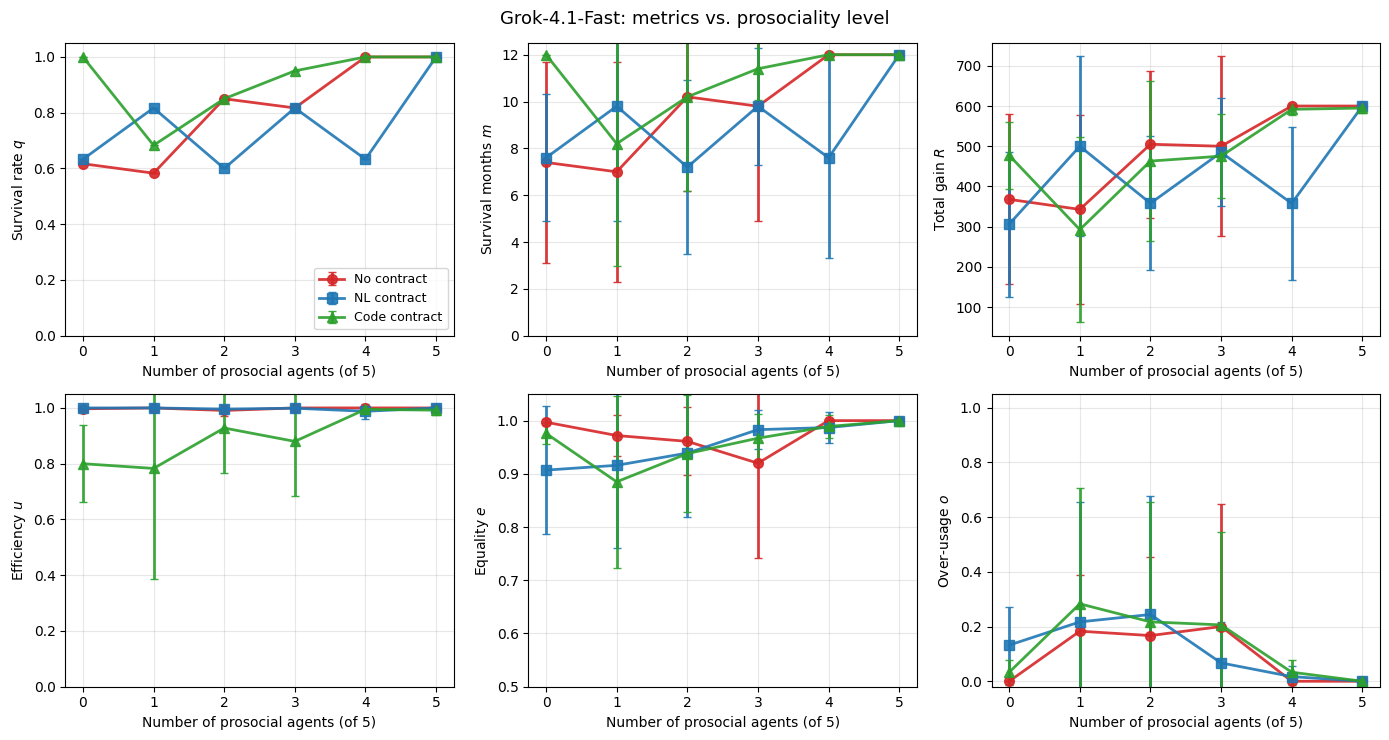

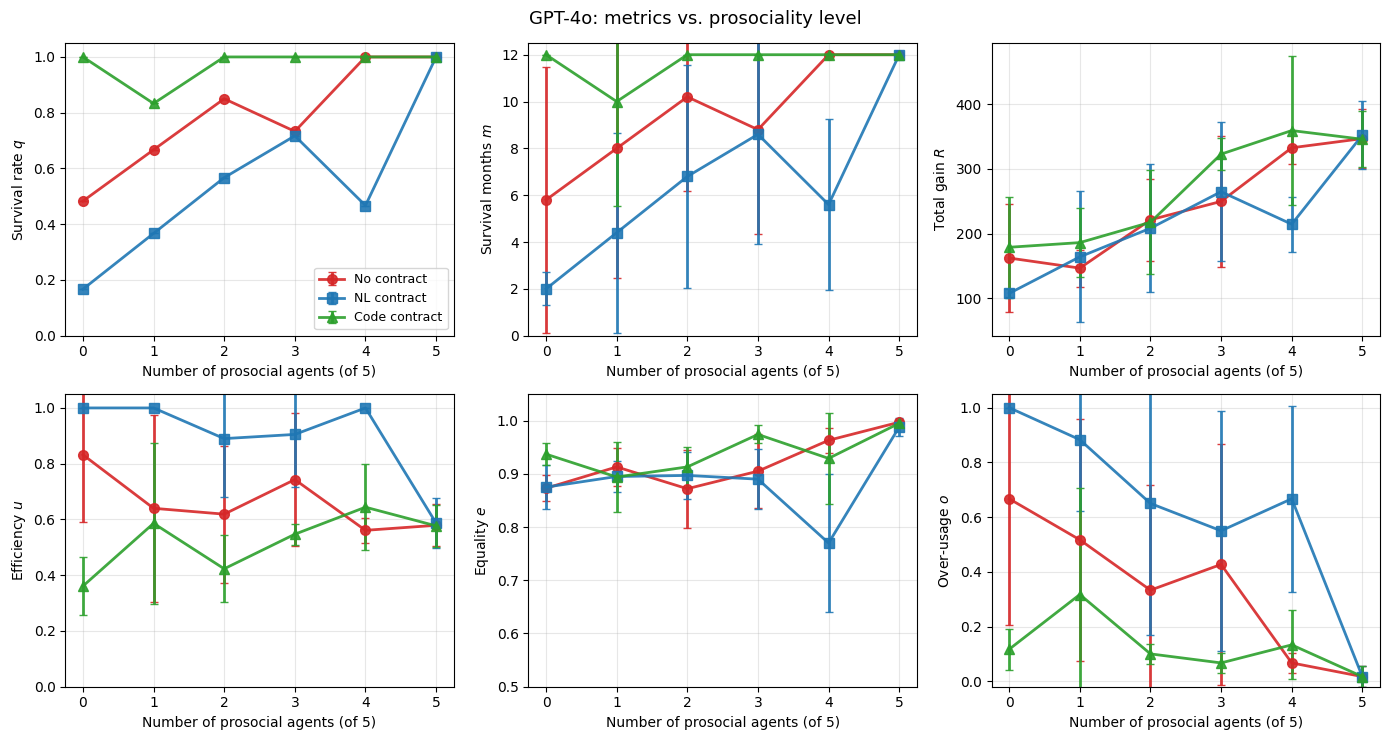

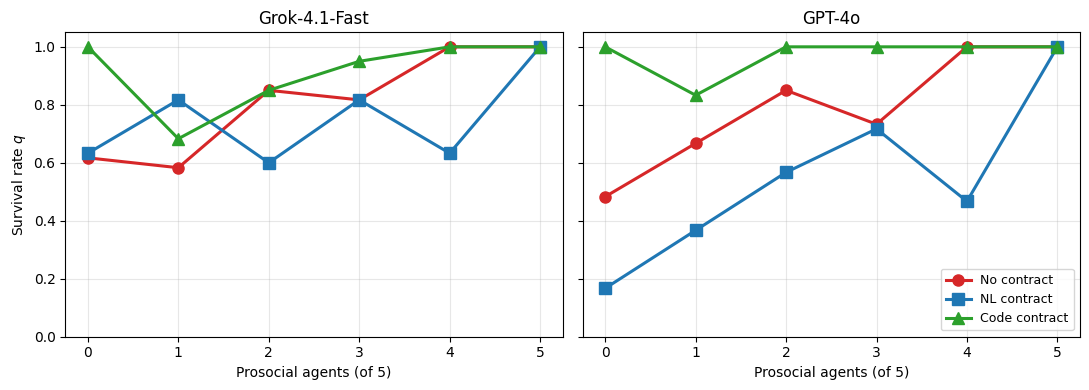

In [2]:

for model, results in MODEL_RESULTS.items():
    safe = model.replace(' ', '_').replace('.', '_')
    plot_model(model, results, savepath=f'prosociality_{safe}.png')
plot_combined_survival(MODEL_RESULTS, savepath='prosociality_survival_combined.png')
plt.show()

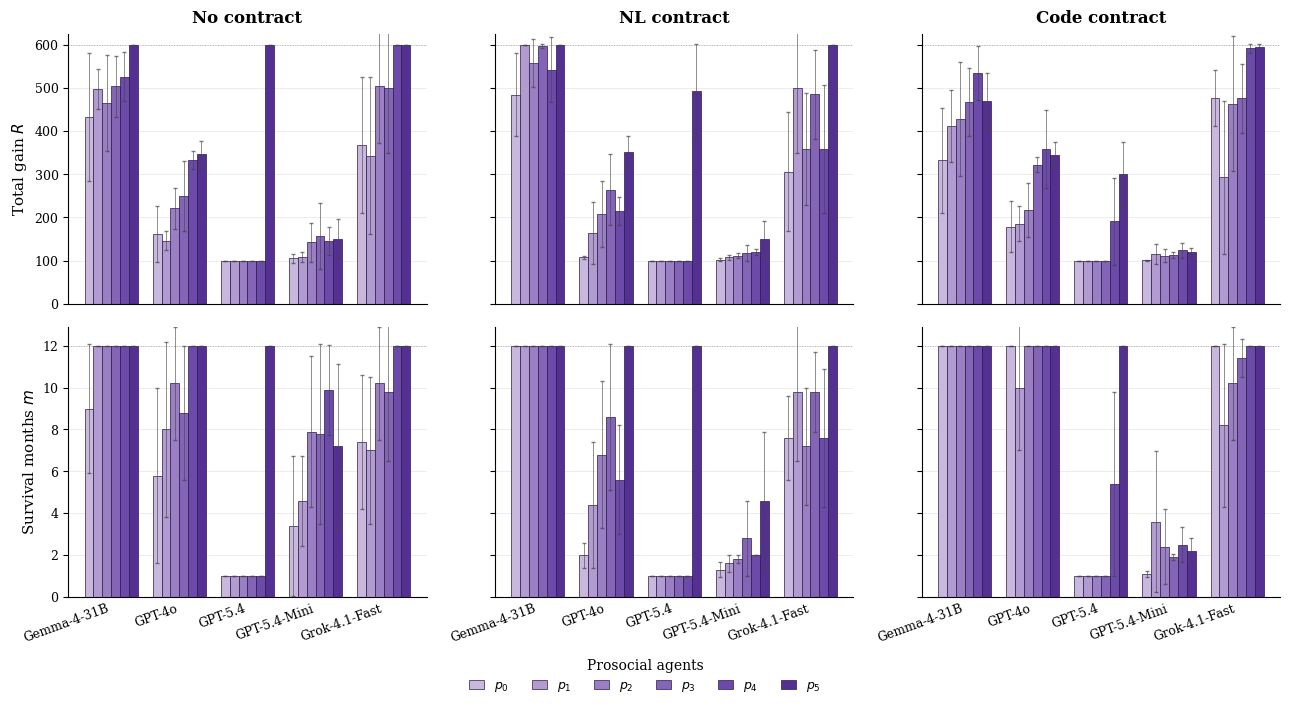

In [ ]:
"""Paper figure: average total gain R and average survival months m,
grouped bars per model, violet gradient bars for prosocial levels p0..p5,
one panel per contract condition, two rows (R and m)."""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

agg = pd.read_csv('aggregated.csv')

# -- Styling --
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['DejaVu Serif', 'Times New Roman', 'Times'],
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'axes.grid.axis': 'y',
    'grid.color': '#dddddd',
    'grid.linewidth': 0.6,
    'grid.alpha': 0.6,
    'axes.axisbelow': True,
})

# Violet gradient for prosocial levels p0..p5 (0 = lightest, 5 = darkest)
# Mimic the image's gradient (light violet -> deep purple)
violet_colors = [
    "#c9b8de",  # p0 - light violet
    "#b19bd1",  # p1
    "#9a7fc4",  # p2
    "#8364b7",  # p3
    "#6c4aaa",  # p4
    "#553093",  # p5 - deep purple
]

p_levels = [0, 1, 2, 3, 4, 5]

model_display = {
    'gemma-4-31b':   'Gemma-4-31B',
    'gpt-4o':        'GPT-4o',
    'gpt-5.4':       'GPT-5.4',
    'gpt-5.4-mini':  'GPT-5.4-Mini',
    'grok-4.1-fast': 'Grok-4.1-Fast',
}
model_order = ['gemma-4-31b', 'gpt-4o', 'gpt-5.4', 'gpt-5.4-mini', 'grok-4.1-fast']

cond_order = ['no-contract', 'nl', 'code-law']
cond_title = {
    'no-contract': 'Baseline',
    'nl':          'Constitution',
    'code-law':    'Code Law',
}

# --- Figure layout: 2 rows (gain, survival) x 3 cols (conditions) ---
fig, axes = plt.subplots(2, 3, figsize=(13, 7.0), sharex='col', sharey='row')

n_models = len(model_order)
n_p = len(p_levels)
bar_width = 0.13
group_centers = np.arange(n_models)  # 0, 1, 2, 3, 4

metrics = [
    ('R',  'Total gain $R$',         [0, 625]),
    ('m',  'Survival months $m$',    [0, 12.9]),
]

for row_idx, (metric, ylabel, ylim) in enumerate(metrics):
    hw_col = f'{metric}_hw'
    for col_idx, cond in enumerate(cond_order):
        ax = axes[row_idx, col_idx]
        sub = agg[agg['condition'] == cond]

        for pi, p in enumerate(p_levels):
            vals, errs = [], []
            for m in model_order:
                row = sub[(sub['model'] == m) & (sub['prosocial'] == p)]
                if row.empty:
                    vals.append(0); errs.append(0)
                else:
                    vals.append(float(row[metric].iloc[0]))
                    errs.append(float(row[hw_col].iloc[0]))
            vals = np.array(vals)
            errs = np.array(errs)
            offset = (pi - (n_p - 1) / 2) * bar_width
            ax.bar(
                group_centers + offset, vals,
                width=bar_width,
                color=violet_colors[pi],
                edgecolor='#2a1a4a',
                linewidth=0.5,
                yerr=errs,
                error_kw=dict(ecolor='#444444', elinewidth=0.6, capsize=1.2, alpha=0.7),
                label=f'$p_{p}$' if (row_idx == 0 and col_idx == 0) else None,
            )

        if row_idx == 0:
            ax.set_title(cond_title[cond], pad=8, fontweight='bold')
        if col_idx == 0:
            ax.set_ylabel(ylabel)
        ax.set_xticks(group_centers)
        ax.set_xticklabels([model_display[m] for m in model_order], rotation=20, ha='right')
        ax.set_ylim(ylim)
        ax.tick_params(axis='x', length=0)

        # Reference line: horizon for m, max gain for R
        if metric == 'm':
            ax.axhline(12, color='#888', linestyle=':', linewidth=0.7, zorder=0)
        if metric == 'R':
            ax.axhline(600, color='#888', linestyle=':', linewidth=0.7, zorder=0)

# --- Shared legend (prosocial levels) ---
legend_handles = [
    Patch(facecolor=violet_colors[i], edgecolor='#2a1a4a', linewidth=0.5,
          label=f'$p_{p_levels[i]}$')
    for i in range(n_p)
]
fig.legend(
    handles=legend_handles,
    title='Prosocial agents',
    loc='lower center',
    ncol=n_p,
    bbox_to_anchor=(0.5, -0.015),
    frameon=False,
    columnspacing=1.8,
    handlelength=1.2,
)

fig.tight_layout(rect=[0, 0.05, 1, 1])

plt.show()
# # Save
# out_pdf = '/mnt/user-data/outputs/govsim_gain_survival.pdf'
# out_png = '/mnt/user-data/outputs/govsim_gain_survival.png'
# import os
# os.makedirs('/mnt/user-data/outputs', exist_ok=True)
# fig.savefig(out_pdf, bbox_inches='tight')
# fig.savefig(out_png, bbox_inches='tight', dpi=200)
# print(f"Saved: {out_pdf}")
# print(f"Saved: {out_png}")